<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>تطبيق الطالب · Pneumonia باستخدام PyTorch</h2><p>د. محمد الحبيب</p><p>نفس خطوات شرح المدرّب. أكمل TODO01–06 في مواضعها فقط. استبدل <code dir="ltr">...</code> أو سطر <code dir="ltr">raise NotImplementedError</code> بالحل المطلوب.</p><p>نتابع <bdi dir="ltr">C01–C12</bdi> بالترتيب نفسه في الشرح. <code dir="ltr">TRAIN_NOW=False</code> يحمّل النموذج المرجعي. للتدريب الكامل اختر <code dir="ltr">True</code> وأعد <bdi dir="ltr">C01–C06</bdi> بالترتيب.</p><p>بعد المشروع: <bdi dir="ltr">C13–C14</bdi> لتحدي Fine-tuning قصير، ثم <bdi dir="ltr">C15</bdi> لتذكرة الخروج. الواجب الثلاثي في Notebook منفصلة.</p></div><div style="clear:both"></div></div>

<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C01</bdi> · الأدوات والإعدادات</h2>
<p>نجمع إعدادات التجربة ونختار Device. <code dir="ltr">TRAIN_NOW = False</code> يحمّل النموذج المرفق، و<code dir="ltr">True</code> يدرّب Classifier جديدة؛ لبداية جديدة تُشغّل <bdi dir="ltr">C01–C06</bdi> كاملة، ومنها <bdi dir="ltr">C04</bdi>.</p>
</div>
<div style="clear:both;"></div>
</div>

In [1]:
from pathlib import Path
import copy
import random
import time
import sys
from tqdm import tqdm
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from helpers import show_batch, plot_history, plot_confusion, show_prediction, show_gradcam

# نثبت البداية قدر الإمكان لتسهيل مقارنة التجارب.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

# نضع الإعدادات التي سنغيّرها أثناء التجربة في مكان واحد.
IMAGE_SIZE, BATCH_SIZE, EPOCHS = 224, 32, 3
LEARNING_RATE = 0.001
TRAIN_NOW = False
# النموذج والبيانات يجب أن يكونا على Device نفسها.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/chest_xray")
assert DATA_DIR.is_dir(), "Open Jupyter from your extracted project folder."
# نستخدم Initial Weights المرفقة لتجنب التحميل أثناء الدرس.
torch.hub.set_dir("artifacts/torch")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.6.0+cu124


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C02</bdi> · قراءة الصور وLabels</h2>
<p>نحوّل الصور إلى Tensors بمقاس <bdi dir="ltr">224 × 224</bdi> ونقرأ Labels من أسماء المجلدات. تبقى Train وValidation وTest منفصلة؛ المعالجة نفسها تُستخدم عند Prediction.</p>
<p><b>TODO01: أكمل سطر Train مثل سطري Validation وTest.</b></p></div>
<div style="clear:both;"></div>
</div>

In [2]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
# نطبق العمليات بالترتيب نفسه على كل صورة.
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# أسماء المجلدات تحدد Classes، وTransform تجهز الصورة عند قراءتها.
# TODO01: Read Train using the same ImageFolder pattern below.
train_data = datasets.ImageFolder(DATA_DIR / "train", transform=transform)
val_data = datasets.ImageFolder(DATA_DIR / "val", transform=transform)
test_data = datasets.ImageFolder(DATA_DIR / "test", transform=transform)
class_names = train_data.classes
# نتحقق أن معنى الأرقام متطابق في Train وValidation وTest.
assert class_names == ["NORMAL", "PNEUMONIA"]
assert train_data.class_to_idx == val_data.class_to_idx == test_data.class_to_idx

print("Class mapping:", train_data.class_to_idx)
for name, dataset in [("Train", train_data), ("Validation", val_data), ("Test", test_data)]:
    counts = np.bincount(dataset.targets, minlength=2)
    print(f"{name}: {len(dataset)} images | NORMAL={counts[0]} | PNEUMONIA={counts[1]}")


Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Train: 3834 images | NORMAL=1071 | PNEUMONIA=2763
Validation: 925 images | NORMAL=270 | PNEUMONIA=655
Test: 624 images | NORMAL=234 | PNEUMONIA=390


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C03</bdi> · تجهيز Batches</h2>
<p>يجمع DataLoader الصور في Batches؛ الشكل <code dir="ltr">[N, 3, 224, 224]</code> يعني عدد الصور ثم Channels ثم الارتفاع والعرض. نعرض Batch واحدة للتحقق من الصور وLabels.</p>
</div>
<div style="clear:both;"></div>
</div>

Images: (32, 3, 224, 224) torch.float32
Labels: (32,) torch.int64


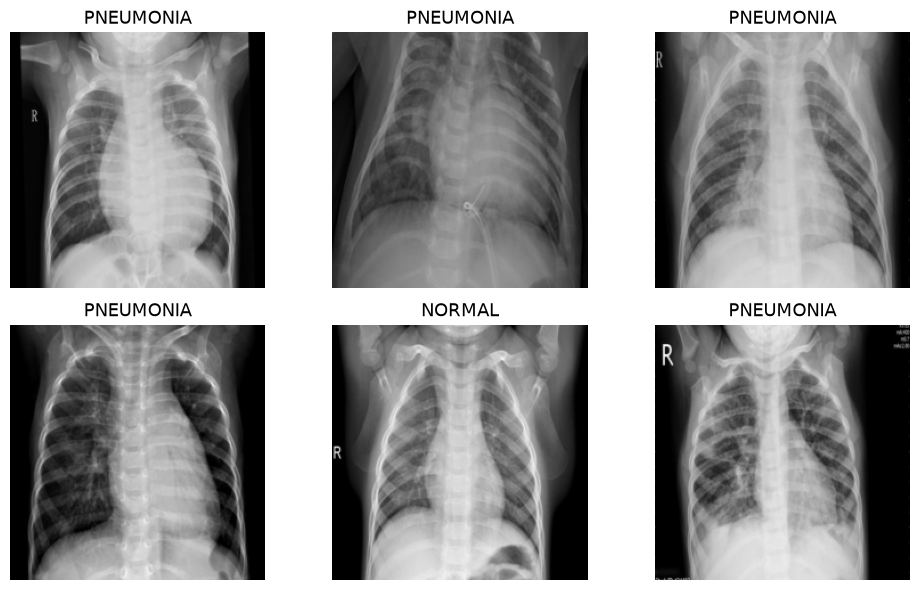

In [3]:
# نجمع الصور في Batches ونخلط Train فقط.
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# نأخذ Batch واحدة لنرى ما يدخل إلى النموذج.
images, labels = next(iter(train_loader))
print("Images:", tuple(images.shape), images.dtype)
print("Labels:", tuple(labels.shape), labels.dtype)
show_batch(images, labels, class_names, MEAN, STD)

<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C04</bdi> · تجهيز MobileNetV2</h2>
<p>نثبّت Backbone الخاصة بـMobileNetV2، ونستبدل آخر Layer لتخرج درجتين. Adam يحدّث Classifier فقط، وCrossEntropyLoss تستقبل Logits مباشرة دون Softmax.</p>
<p><b>TODO02 وTODO03: أكمل Linear الأخيرة وLoss كما في الشرح.</b></p></div>
<div style="clear:both;"></div>
</div>

In [4]:
# نبدأ من Weights تعلمت Features عامة على ImageNet.
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)

# نثبت Backbone وندرّب Classifier الجديدة فقط.
for parameter in model.features.parameters():
    parameter.requires_grad = False
# آخر Layer تخرج درجة لكل Class في مشروعنا.
# TODO02: Replace the next line with the classifier assignment from C04.
model.classifier[-1] = nn.Linear(model.last_channel, len(class_names))
model = model.to(device)
# هذه Loss تستقبل Logits مباشرة، لذلك لا نضيف Softmax هنا.
# TODO03: Choose the loss for raw class logits.
loss_fn = nn.CrossEntropyLoss()
# نعطي Optimizer Parameters الخاصة بـClassifier فقط.
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Classifier:", model.classifier)
print("Trainable parameters:", trainable)


Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)
Trainable parameters: 2562


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C05</bdi> · تعريف Training Loop</h2>
<p>الدالة <code dir="ltr">run_epoch</code> تعالج مرورًا واحدًا على البيانات. <code dir="ltr">training=True</code> يحسب Gradients ويحدّث Weights؛ <code dir="ltr">False</code> يقيس الأداء فقط، وتعريف الدالة هنا لا يشغّل التدريب.</p>
<p><b>TODO04: اكتب سطري Backward وStep في المكان نفسه داخل الدالة.</b></p></div>
<div style="clear:both;"></div>
</div>

In [5]:
def run_epoch(loader, training):
    # نفعّل Training behavior أو Evaluation behavior حسب المرحلة.
    model.train(training)
    # نبقي Backbone ثابتة، بما فيها إحصاءات BatchNorm.
    model.features.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    phase = "Training" if training else "Validation"

    # يظهر Progress Bar قبل قراءة أول Batch، ويتحدث بعد اكتمالها.
    with tqdm(total=len(loader), desc=phase, unit="batch",
              file=sys.stdout, dynamic_ncols=True, mininterval=0.5) as progress:
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                # نبدأ Batch جديدة بدون Gradients متراكمة من السابقة.
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                # Forward Pass ثم قياس الخطأ مقارنةً بـLabels الصحيحة.
                logits = model(x)
                loss = loss_fn(logits, y)
                if training:
                    # نحسب Gradients أولًا، ثم نحدّث Weights.
                    # TODO04: Calculate gradients, then update weights.
                    loss.backward()
                    optimizer.step()
            # نزن Loss بعدد الصور؛ آخر Batch قد تكون أصغر.
            total_loss += loss.item() * len(y)
            # == تقارن Prediction بـLabel؛ نجمع عدد الإجابات الصحيحة.
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total += len(y)

            # المتوسط محسوب على الصور التي اكتملت حتى الآن.
            progress.set_postfix(Loss=f"{total_loss / total:.4f}",
                                 Accuracy=f"{total_correct / total:.1%}", refresh=False)
            progress.update(1)
    return total_loss / total, total_correct / total


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C06</bdi> · تشغيل التجربة</h2>
<p>هنا يبدأ التدريب أو تحميل النموذج المرفق حسب <code dir="ltr">TRAIN_NOW</code>. عند التدريب يظهر Progress لكل Batch، ثم تُستعاد Weights الخاصة بأقل Validation Loss.</p>
</div>
<div style="clear:both;"></div>
</div>

In [6]:
run_source = None
print(f"C06 started | TRAIN_NOW={TRAIN_NOW} | Device={device}", flush=True)
if TRAIN_NOW:
    if not isinstance(EPOCHS, int) or EPOCHS < 1:
        raise ValueError("EPOCHS must be a positive integer.")
    print(f"Starting training: {EPOCHS} epoch(s) | "
          f"Train: {len(train_loader)} batches | Validation: {len(val_loader)} batches",
          flush=True)
    history = []
    best_loss, best_epoch, best_state = float("inf"), 0, None
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        print(f"\nEpoch {epoch}/{EPOCHS}", flush=True)
        train_loss, train_acc = run_epoch(train_loader, training=True)
        val_loss, val_acc = run_epoch(val_loader, training=False)
        history.append([train_loss, val_loss, train_acc, val_acc])
        print(f"Epoch {epoch}: Train loss={train_loss:.3f}, acc={train_acc:.1%} | "
              f"Val loss={val_loss:.3f}, acc={val_acc:.1%}", flush=True)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            # نسخة مستقلة من أفضل Weights حتى الآن.
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    training_seconds = time.perf_counter() - started
    run_source = "trained_here"
    print(f"Training complete. Selected epoch: {best_epoch}; "
          f"training time: {training_seconds:.1f} seconds", flush=True)
else:
    print("Loading bundled reference model...", flush=True)
    reference = torch.load("artifacts/pneumonia_reference.pt", map_location="cpu", weights_only=True)
    model.load_state_dict(reference["state_dict"])
    history, best_epoch = reference["history"], reference["best_epoch"]
    training_seconds = 0.0
    run_source = "bundled_reference"
    print("Loaded the bundled reference model. No training was run in this session.", flush=True)

C06 started | TRAIN_NOW=False | Device=cuda


Loading bundled reference model...


Loaded the bundled reference model. No training was run in this session.


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C07</bdi> · قراءة Learning Curves</h2>
<p>الرسم يعرض <code dir="ltr">history</code> للمصدر المطبوع أدناه. في المرجع تنخفض Validation Loss؛ انخفاض Train Loss مع ارتفاع Validation Loss عبر عدة Epochs قد يشير إلى Overfitting، وضعف الأداء على المجموعتين قد يشير إلى Underfitting.</p>
</div>
<div style="clear:both;"></div>
</div>

Run source: bundled_reference


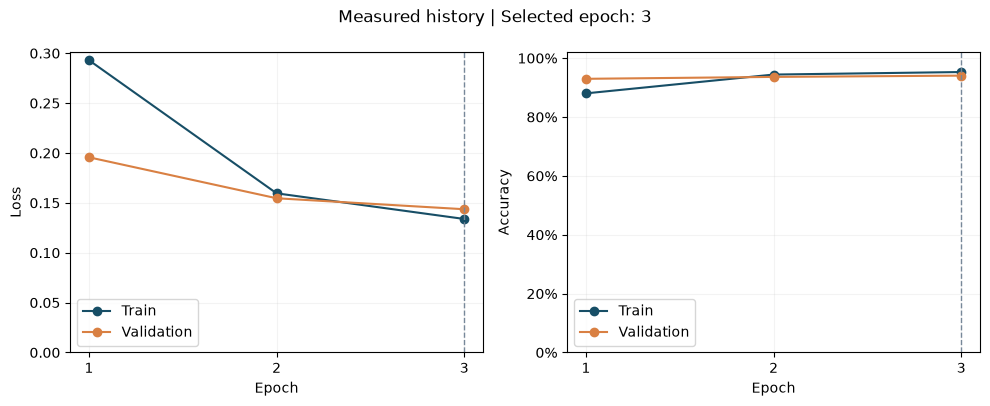

In [7]:
# نرسم القياسات المسجلة فعلًا، مع تحديد مصدرها.
print("Run source:", run_source)
plot_history(history, best_epoch)

<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C08</bdi> · التقييم على Test</h2>
<p>نقيّم النموذج المختار على جميع صور Test البالغ عددها 624 دون تحديث Weights. Accuracy وRecall وConfusion Matrix تصف النتائج؛ في المصفوفة الصفوف للحقيقة والأعمدة للتوقعات.</p>
</div>
<div style="clear:both;"></div>
</div>

Test accuracy: 77.4%
PNEUMONIA recall: 97.9%
NORMAL recall (specificity): 43.2%
Rows = true labels; columns = predictions


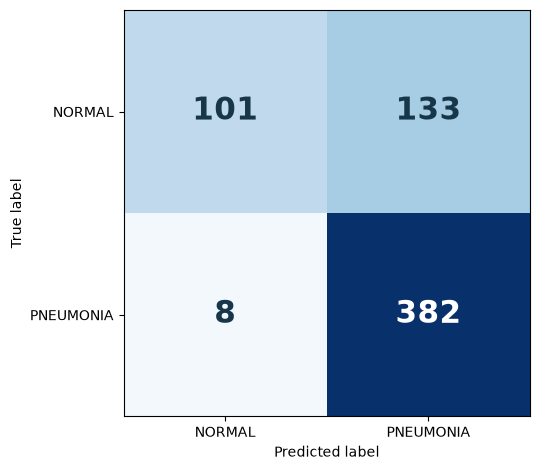

In [8]:
model.eval()
true_labels, predicted_labels = [], []
# نقيس الأداء بدون حساب Gradients أو تحديث Weights.
with torch.inference_mode():
    for x, y in test_loader:
        logits = model(x.to(device))
        true_labels.extend(y.tolist())
        predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())

test_accuracy = accuracy_score(true_labels, predicted_labels)
pneumonia_recall = recall_score(true_labels, predicted_labels, pos_label=1)
normal_recall = recall_score(true_labels, predicted_labels, pos_label=0)
cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1])
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"PNEUMONIA recall: {pneumonia_recall:.1%}")
print(f"NORMAL recall (specificity): {normal_recall:.1%}")
print("Rows = true labels; columns = predictions")
plot_confusion(cm, class_names)

<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C09</bdi> · حفظ النموذج وإعادة تحميله</h2>
<p>نحفظ Weights وأسماء Classes وإعدادات المعالجة في Checkpoint، ثم نعيد تحميلها إلى نموذج جديد. حفظ هذه المعلومات يتيح استخدام المعالجة نفسها وفهم ترتيب المخرجات.</p>
</div>
<div style="clear:both;"></div>
</div>

In [9]:
# نحفظ مصدر النموذج الذي اكتمل في C06، مع Weights وإعدادات المعالجة.
assert run_source in {"trained_here", "bundled_reference"}, "Complete C06 first."
checkpoint = {
    "state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "mean": MEAN,
    "std": STD,
    "architecture": "mobilenet_v2",
    "best_epoch": best_epoch,
    "history": history,
    "run_source": run_source,
}
Path("artifacts").mkdir(exist_ok=True)
torch.save(checkpoint, "artifacts/pneumonia_classroom.pt")

# نفتح الملف في نموذج جديد للتأكد أن الحفظ قابل للاستخدام.
saved = torch.load("artifacts/pneumonia_classroom.pt", map_location="cpu", weights_only=True)
deployed_model = models.mobilenet_v2(weights=None)
deployed_model.classifier[-1] = nn.Linear(deployed_model.last_channel, len(saved["class_names"]))
deployed_model.load_state_dict(saved["state_dict"])
deployed_model = deployed_model.to(device).eval()
print("Saved and reloaded: artifacts/pneumonia_classroom.pt")

Saved and reloaded: artifacts/pneumonia_classroom.pt


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C10</bdi> · تعريف Prediction لصورة واحدة</h2>
<p>الدالة <code dir="ltr">predict</code> تعالج صورة واحدة وتعيد Label وScores لكل فئة. تضيف <code dir="ltr">unsqueeze(0)</code> محور Batch، وتحوّل Softmax Logits إلى Scores للعرض؛ Scores ليست احتمالات تشخيص طبي معايرة.</p>
<p><b>TODO05: أضف Batch dimension للصورة نفسها كما في الشرح.</b></p></div>
<div style="clear:both;"></div>
</div>

In [10]:
# نعيد المعالجة نفسها التي حفظناها مع Checkpoint.
prediction_transform = transforms.Compose([
    transforms.Resize((saved["image_size"], saved["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(saved["mean"], saved["std"]),
])

def predict(image_path):
    image = Image.open(image_path).convert("RGB")
    # نضيف بُعد Batch: صورة واحدة تصبح [1, 3, 224, 224].
    # TODO05: Transform the image, add a batch dimension, and move to device.
    x = prediction_transform(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        # Softmax للعرض بعد Prediction، وليست قبل Training Loss.
        scores = deployed_model(x).softmax(dim=1)[0].cpu()
    index = int(scores.argmax().item())
    # Dictionary: اسم Class، ثم Score لكل Class.
    return {"label": saved["class_names"][index],
            "scores": {name: float(scores[i]) for i, name in enumerate(saved["class_names"])}}


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C11</bdi> · تجربة صورة حقيقية</h2>
<p>نستخدم الصورة 234 ونقارن Prediction بالـLabel الصحيحة. الصورة 0 مثال خطأ للنموذج المرجعي؛ فحص الأمثلة يساعدنا على فهم النتيجة دون استخدام Test لاختيار الإعدادات.</p>
</div>
<div style="clear:both;"></div>
</div>

Dataset label: PNEUMONIA
Prediction: PNEUMONIA


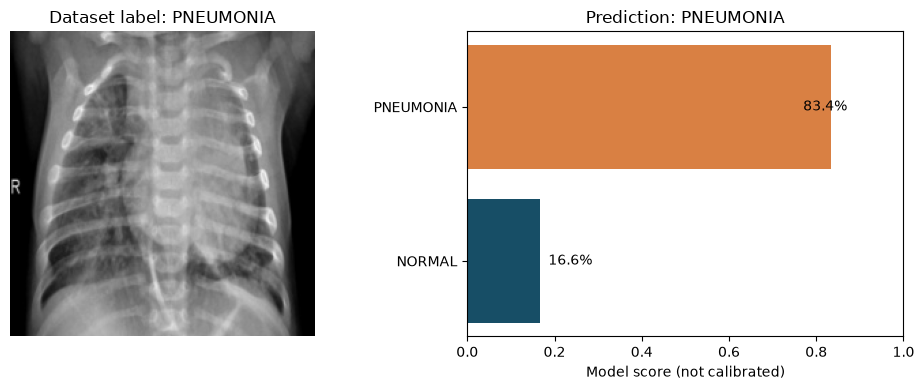

In [11]:
EXAMPLE_INDEX = 234
# كل عنصر في samples هو زوج: مسار الصورة وLabel الصحيحة.
image_path, known_label = test_data.samples[EXAMPLE_INDEX]
result = predict(image_path)
print("Dataset label:", class_names[known_label])
print("Prediction:", result["label"])
show_prediction(image_path, result, true_label=class_names[known_label])

<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">C12</bdi> · قراءة Grad-CAM</h2>
<p>تعرض Grad-CAM مساهمة مناطق الصورة في Prediction: الأزرق منخفض والأحمر مرتفع، بمقياس نسبي داخل الصورة. الخريطة تفسير تقريبي ولا تحدد حدود المرض.</p>
</div>
<div style="clear:both;"></div>
</div>

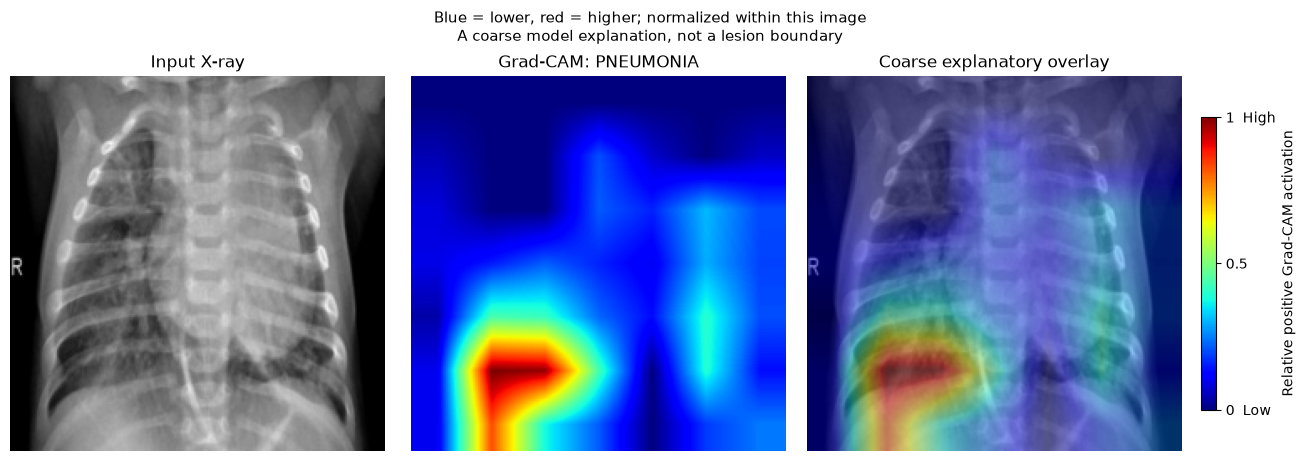

Explained class: PNEUMONIA


In [12]:
# نفس الصورة ونفس النموذج؛ نحسب التفسير بدون تحديث Weights.
cam_info = show_gradcam(deployed_model, image_path, prediction_transform,
                        saved["class_names"], device)
print("Explained class:", cam_info["target_class"])

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>C13 · تحدي Fine-tuning</h2><p>بعد إكمال <bdi dir="ltr">C01–C12</bdi>، نسمح لآخر Feature block بالتحديث مع Classifier، ونستخدم Learning Rate أصغر. نبدأ من Checkpoint نفسها في كل محاولة.</p><p><b>TODO06:</b> اجعل <code dir="ltr">requires_grad</code> في الحلقة الثانية تسمح بالتعلّم. دالة <code dir="ltr">run_epoch(loader, training)</code> هي نفسها. <code dir="ltr">features.eval()</code> تثبّت سلوك BatchNorm، لكنها لا تمنع Gradients للأوزان التي فتحناها.</p></div><div style="clear:both"></div></div>

In [13]:
from torch.utils.data import Subset

# Start each challenge attempt from the checkpoint created in C09.
model.load_state_dict(saved["state_dict"])
torch.manual_seed(SEED)
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Allow only the last feature block to adapt to our X-rays.
for parameter in model.features[-1].parameters():
    # TODO06: Enable gradients for this last block.
    parameter.requires_grad = True

# Include the newly trainable parameters with a smaller learning rate.
optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=0.0001
)
trainable_names = [name for name, p in model.named_parameters() if p.requires_grad]
assert any(name.startswith("features.") for name in trainable_names)
assert all(name.startswith(("features.18.", "classifier.")) for name in trainable_names)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("BatchNorm statistics remain fixed inside run_epoch.")


Trainable parameters: 414722
BatchNorm statistics remain fixed inside run_epoch.


<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>C14 · تشغيل التحدي وقراءة النتيجة</h2><p>ننفّذ 10 Batches فقط، أي 320 صورة من Train، ثم نقيس جميع صور Validation قبل التحديث وبعده. هذه تجربة تدريب قصيرة على جزء من Train. قد تتحسن النتيجة أو تتراجع.</p><p>نحتفظ بالتقييم السابق على Test بوصفه نتيجة النموذج الأساسي. الصور في <bdi dir="ltr">C11–C12</bdi> تخص النموذج الأساسي أيضًا. يُحفظ نموذج التحدي منفصلًا باسم <code dir="ltr">pneumonia_finetuned.pt</code>.</p></div><div style="clear:both"></div></div>

In [14]:
# A short training subset keeps the exercise practical on CPU as well.
FT_BATCHES = 10
indices = torch.randperm(len(train_data), generator=torch.Generator().manual_seed(SEED))
ft_data = Subset(train_data, indices[:FT_BATCHES * BATCH_SIZE].tolist())
ft_loader = DataLoader(ft_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                       generator=torch.Generator().manual_seed(SEED))

# Use Validation before and after; Test is not used to select an experiment.
before_loss, before_accuracy = run_epoch(val_loader, training=False)
ft_train_loss, ft_train_accuracy = run_epoch(ft_loader, training=True)
after_loss, after_accuracy = run_epoch(val_loader, training=False)
ft_results = {
    "train_images": len(ft_data), "train_batches": len(ft_loader), "lr": 0.0001,
    "before_val_loss": before_loss, "after_val_loss": after_loss,
    "before_val_accuracy": before_accuracy, "after_val_accuracy": after_accuracy,
}
print("Fine-tuning comparison:", ft_results)
print("This used a training subset, not a full Train epoch.")

# Keep the challenge model separate from the original classroom checkpoint.
ft_checkpoint = dict(checkpoint)
ft_checkpoint["state_dict"] = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
ft_checkpoint["run_source"] = "short_finetuning_challenge"
ft_checkpoint["fine_tuning_results"] = ft_results
ft_checkpoint.pop("history", None)
ft_checkpoint.pop("best_epoch", None)
torch.save(ft_checkpoint, "artifacts/pneumonia_finetuned.pt")

Validation:   0%|          | 0/29 [00:00<?, ?batch/s]

Validation:   3%|▎         | 1/29 [00:01<00:31,  1.14s/batch, Accuracy=90.6%, Loss=0.1677]

Validation:   7%|▋         | 2/29 [00:02<00:28,  1.05s/batch, Accuracy=85.9%, Loss=0.2752]

Validation:  10%|█         | 3/29 [00:03<00:26,  1.03s/batch, Accuracy=87.5%, Loss=0.2678]

Validation:  14%|█▍        | 4/29 [00:04<00:25,  1.02s/batch, Accuracy=87.5%, Loss=0.2642]

Validation:  17%|█▋        | 5/29 [00:05<00:24,  1.02s/batch, Accuracy=86.2%, Loss=0.2891]

... (57 outputs left out)

Validation:  90%|████████▉ | 26/29 [00:16<00:01,  1.56batch/s, Accuracy=95.2%, Loss=0.1316]

Validation:  97%|█████████▋| 28/29 [00:17<00:00,  1.74batch/s, Accuracy=95.1%, Loss=0.1324]

Validation: 100%|██████████| 29/29 [00:17<00:00,  1.63batch/s, Accuracy=95.1%, Loss=0.1310]


Fine-tuning comparison: {'train_images': 320, 'train_batches': 10, 'lr': 0.0001, 'before_val_loss': 0.1436180909420993, 'after_val_loss': 0.13099322361720575, 'before_val_accuracy': 0.9405405405405406, 'after_val_accuracy': 0.9513513513513514}
This used a training subset, not a full Train epoch.


<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>C15 · تذكرة الخروج والتسليم</h2><p>اكتب اسمك وإجاباتك، ثم احفظ Notebook باسمك. التسليم: Notebook + <code dir="ltr">Pneumonia_Class_Submission.zip</code>. يحتوي ZIP على مقارنة Validation، وتذكرة الخروج، وصورتي Prediction وGrad-CAM للنموذج الأساسي.</p><p>التقييم من 10: إكمال TODO01–05 أربع نقاط، فتح آخر Block مع Optimizer المناسبة نقطتان، قراءة مقارنة Validation نقطتان، وحدود Grad-CAM واكتمال التسليم نقطتان. لا يشترط تحسن الدقة.</p></div><div style="clear:both"></div></div>

In [15]:
import csv
import zipfile

# Write your own explanation; a lower Validation loss is not guaranteed.
answers = {
    "student_name": "MOHAMMED ALANSI",
    "what_changed": "تم فتح التدرجات وتدريب آخر كتلة ميزات في MobileNetV2 (features[-1] / features.18) مع المصنف Classifier باستخدام معدل تعلم مخفض (0.0001).",
    "what_happened_in_validation": "تم قياس دقة وخسارة التحقق قبل وبعد تدريب 10 دفعات (320 صورة) لمراقبة استجابة النموذج مع ثبات إحصاءات BatchNorm.",
    "why_gradcam_is_not_a_diagnosis": "خريطة Grad-CAM تقدم تفسيرا تقريبيا لمناطق تركيز النموذج الإيجابية، ولا تحدد حدود الآفة المرضية بدقة ولا تعد بديلا عن التشخيص الطبي المتخصص.",
}
assert all(value.strip() and not value.startswith("YOUR") for value in answers.values()), "Complete all exit-ticket answers."
output_dir = Path("student_outputs")
output_dir.mkdir(exist_ok=True)
with (output_dir / "finetuning_comparison.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(ft_results))
    writer.writeheader()
    writer.writerow(ft_results)
(output_dir / "exit_ticket.txt").write_text(
    "\n\n".join(f"{key}: {value}" for key, value in answers.items()), encoding="utf-8"
)
with zipfile.ZipFile("Pneumonia_Class_Submission.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in [output_dir / "finetuning_comparison.csv", output_dir / "exit_ticket.txt",
                 Path("assets/prediction.png"), Path("assets/gradcam.png")]:
        if not path.is_file():
            raise FileNotFoundError(f"Complete the earlier cells first: {path}")
        archive.write(path, path.name)
print("Submit your saved notebook and Pneumonia_Class_Submission.zip.")


Submit your saved notebook and Pneumonia_Class_Submission.zip.
